# NPH Cerebellum - LIGER Default vs Best UMAP

Fixed seed: `1`. Left column: cell type. Right column: batch.
Default is the top row and Best is the bottom row. Each column uses one shared legend.

Selection deltas for this seed: bio `+0.067679`,
batch `+0.216406`, joint `+0.127170`.


In [1]:
import gc
import importlib.util
import os
import sys

os.environ["PYTHONNOUSERSITE"] = "1"
sys.path = [
    path
    for path in sys.path
    if ".local/lib/python3.10/site-packages" not in path
]

PROJECT_ROOT = '/ubc/cs/research/beaver/projects/Single-cell-integration-metrics'
os.environ["R_HOME"] = f"{PROJECT_ROOT}/CondaEnv/pyliger_env/lib/R"
sys.path.insert(0, f"{PROJECT_ROOT}/scib/")

import anndata as ad
import numpy as np
import pandas as pd

OPTIMIZER_PATH = (
    f"{PROJECT_ROOT}/scripts/optuna_multi_metrics/"
    "optuna_liger/optimize_liger_multi_metrics.py"
)
optimizer_spec = importlib.util.spec_from_file_location(
    "liger_opt",
    OPTIMIZER_PATH,
)
if optimizer_spec is None or optimizer_spec.loader is None:
    raise ImportError(f"Cannot load LIGER optimizer: {OPTIMIZER_PATH}")
liger_opt = importlib.util.module_from_spec(optimizer_spec)
sys.modules[optimizer_spec.name] = liger_opt
optimizer_spec.loader.exec_module(liger_opt)


/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/CondaEnv/pyliger_env/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
DATASET_NAME = 'nph_cerebellum'
DATA_PATH = f"{PROJECT_ROOT}/data/{DATASET_NAME}.h5ad"
BATCH_KEY = 'Sample'
LABEL_KEY = 'Celltype'

SELECTED_BIO_METRICS = ('BAMI', 'CASW', 'SCGRAPHM')
SELECTED_BATCH_METRICS = ('BRAS', 'KBET', 'CPCR')
SELECTED_METRICS = SELECTED_BIO_METRICS + SELECTED_BATCH_METRICS

SEEDS = tuple(range(1, 11))
MODE = "core"
LAYER = "counts"
N_NEIGHBORS = 15
EMBED_KEY = "X_liger"

liger_opt.DATASET_NAME = DATASET_NAME
liger_opt.DATA_PATH = DATA_PATH
liger_opt.BATCH_KEY = BATCH_KEY
liger_opt.LABEL_KEY = LABEL_KEY
liger_opt.MODE = MODE
liger_opt.LAYER = LAYER
liger_opt.USE_BAMI = "BAMI" in SELECTED_METRICS
liger_opt.USE_CASW = "CASW" in SELECTED_METRICS
liger_opt.USE_SCGRAPHM = "SCGRAPHM" in SELECTED_METRICS
liger_opt.USE_TRAJ = "TRAJ" in SELECTED_METRICS
liger_opt.USE_ISOLISI = "ISOLISI" in SELECTED_METRICS
liger_opt.USE_BRAS = "BRAS" in SELECTED_METRICS
liger_opt.USE_KBET = "KBET" in SELECTED_METRICS
liger_opt.USE_CPCR = "CPCR" in SELECTED_METRICS

assert DATASET_NAME == 'nph_cerebellum'
assert BATCH_KEY == 'Sample'
assert LABEL_KEY == 'Celltype'
assert SELECTED_METRICS == ('BAMI', 'CASW', 'SCGRAPHM', 'BRAS', 'KBET', 'CPCR')
assert SEEDS == tuple(range(1, 11))
assert liger_opt.CORE_MAX_ITERS == 30
assert liger_opt.N_NEIGHBORS == N_NEIGHBORS
assert liger_opt.EMBED_KEY == EMBED_KEY

pd.Series(
    {
        "dataset": DATASET_NAME,
        "data_path": DATA_PATH,
        "batch_key": BATCH_KEY,
        "label_key": LABEL_KEY,
        "metrics": list(SELECTED_METRICS),
        "seeds": list(SEEDS),
        "mode": MODE,
        "layer": LAYER,
    },
    name="configuration",
)


dataset                                         nph_cerebellum
data_path    /ubc/cs/research/beaver/projects/Single-cell-i...
batch_key                                               Sample
label_key                                             Celltype
metrics               [BAMI, CASW, SCGRAPHM, BRAS, KBET, CPCR]
seeds                          [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
mode                                                      core
layer                                                   counts
Name: configuration, dtype: object

In [3]:
from pathlib import Path
import anndata as ad
import matplotlib.pyplot as plt
import scanpy as sc
from IPython.display import Image, display
from matplotlib.lines import Line2D

METHOD_NAME = 'LIGER'
DATASET_DISPLAY = 'NPH Cerebellum'
SEED = 1
UMAP_ROOT = Path(
    PROJECT_ROOT,
    "notebooks",
    "optuna_multimetrics_tests",
    "UMAP",
)
FIGURE_ROOT = UMAP_ROOT / "figures"
FIGURE_ROOT.mkdir(parents=True, exist_ok=True)
FIGURE_STEM = 'nph_cerebellum_liger_seed1_default_vs_best_umap'
PNG_PATH = FIGURE_ROOT / f"{FIGURE_STEM}.png"
SVG_PATH = FIGURE_ROOT / f"{FIGURE_STEM}.svg"

assert DATASET_NAME == 'nph_cerebellum'
assert SEED == 1

pd.Series(
    {
        "dataset": DATASET_NAME,
        "method": METHOD_NAME,
        "seed": SEED,
        "cell_type_key": LABEL_KEY,
        "batch_key": BATCH_KEY,
        "embedding_key": EMBED_KEY,
        "png": str(PNG_PATH),
        "svg": str(SVG_PATH),
    },
    name="umap_configuration",
)


dataset                                             nph_cerebellum
method                                                       LIGER
seed                                                             1
cell_type_key                                             Celltype
batch_key                                                   Sample
embedding_key                                              X_liger
png              /ubc/cs/research/beaver/projects/Single-cell-i...
svg              /ubc/cs/research/beaver/projects/Single-cell-i...
Name: umap_configuration, dtype: object

In [4]:
liger_opt.validate_metric_dependencies()
liger_opt.validate_configuration(list(SELECTED_METRICS))
liger_opt.validate_dataset_contents()


Dataset preflight: n_obs=84619 n_batches=2 n_labels=8
CPCR preflight: eligible_labels=8


In [5]:
LIGER_DEFAULT_ARGS = {
    "k": 20,
    "value_lambda": 5.0,
    "max_iters": 30,
    "mode": "core",
    "layer": "counts",
}


def run_liger_default(adata, seed):
    return liger_opt.run_liger(
        adata=adata,
        k=LIGER_DEFAULT_ARGS["k"],
        lam=LIGER_DEFAULT_ARGS["value_lambda"],
        max_iterations=LIGER_DEFAULT_ARGS["max_iters"],
        mode=LIGER_DEFAULT_ARGS["mode"],
        layer=LIGER_DEFAULT_ARGS["layer"],
        seed=seed,
    )


pd.Series(LIGER_DEFAULT_ARGS, name="default_setting")


k                   20
value_lambda       5.0
max_iters           30
mode              core
layer           counts
Name: default_setting, dtype: object

In [6]:
print(f"Running Default with seed {SEED}", flush=True)
adata_default = run_liger_default(
    ad.read_h5ad(DATA_PATH),
    seed=SEED,
)
assert EMBED_KEY in adata_default.obsm
assert adata_default.obsm[EMBED_KEY].shape[0] == adata_default.n_obs
assert np.isfinite(adata_default.obsm[EMBED_KEY]).all()
adata_default


Running Default with seed 1


/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/CondaEnv/pyliger_env/lib/python3.10/site-packages/numba/np/ufunc/dufunc.py:344: NumbaWarning: Compilation requested for previously compiled argument types ((uint32,)). This has no effect and perhaps indicates a bug in the calling code (compiling a ufunc more than once for the same signature
/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/CondaEnv/pyliger_env/lib/python3.10/site-packages/numba/np/ufunc/dufunc.py:344: NumbaWarning: Compilation requested for previously compiled argument types ((uint32,)). This has no effect and perhaps indicates a bug in the calling code (compiling a ufunc more than once for the same signature
/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/CondaEnv/pyliger_env/lib/python3.10/site-packages/numba/np/ufunc/dufunc.py:344: NumbaWarning: Compilation requested for previously compiled argument types ((uint32,)). This has no effect and perhaps indicates a bug in the

Removing 1023 genes not expressing in FM3.


Removing 246 genes not expressing in MM1.


[LIGER PARAMS] function=optimize_ALS k=20 value_lambda=5.0 max_iters=30 rand_seed=1


...

 97%|█████████▋| 29/30 [02:54<00:06,  6.02s/it]

100%|██████████| 30/30 [03:00<00:00,  6.02s/it]

100%|██████████| 30/30 [03:00<00:00,  6.02s/it]

[LIGER PARAMS] function=quantile_norm rand_seed=1


AnnData object with n_obs × n_vars = 84619 × 18892
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'Batch', 'percent.mt', 'seurat_clusters', 'Sample', 'Tissue', 'Celltype', 'Abbreviation'
    var: 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'seurat_v3_highly_variable', 'dispersions', 'dispersions_norm'
    uns: 'hvg', 'log1p', 'neighbors', 'pca', 'umap'
    obsm: 'X_pca', 'X_umap', 'X_liger'
    varm: 'PCs'
    layers: 'counts', 'orig_counts'
    obsp: 'connectivities', 'distances'

In [7]:
OPTUNA_STUDY_NAME = 'liger_nph_cerebellum_joint_expanded_metrics_scgraphm_v1'
OPTUNA_BEST_TRIAL = 15
OPTUNA_BEST_VALUE = 0.7457946872944343
OPTUNA_BEST_PARAMS = {'k': 32, 'value_lambda': 0.5033965087804688}

LIGER_BEST_ARGS = {
    "k": OPTUNA_BEST_PARAMS["k"],
    "value_lambda": OPTUNA_BEST_PARAMS["value_lambda"],
    "max_iters": 30,
    "mode": "core",
    "layer": "counts",
}


def run_liger_best(adata, seed):
    return liger_opt.run_liger(
        adata=adata,
        k=LIGER_BEST_ARGS["k"],
        lam=LIGER_BEST_ARGS["value_lambda"],
        max_iterations=LIGER_BEST_ARGS["max_iters"],
        mode=LIGER_BEST_ARGS["mode"],
        layer=LIGER_BEST_ARGS["layer"],
        seed=seed,
    )


pd.Series(
    {
        "study": OPTUNA_STUDY_NAME,
        "best_trial": OPTUNA_BEST_TRIAL,
        "best_value": OPTUNA_BEST_VALUE,
        **LIGER_BEST_ARGS,
    },
    name="best_setting",
)


study           liger_nph_cerebellum_joint_expanded_metrics_sc...
best_trial                                                     15
best_value                                               0.745795
k                                                              32
value_lambda                                             0.503397
max_iters                                                      30
mode                                                         core
layer                                                      counts
Name: best_setting, dtype: object

In [8]:
print(f"Running Best with seed {SEED}", flush=True)
adata_best = run_liger_best(
    ad.read_h5ad(DATA_PATH),
    seed=SEED,
)
assert EMBED_KEY in adata_best.obsm
assert adata_best.obsm[EMBED_KEY].shape[0] == adata_best.n_obs
assert np.isfinite(adata_best.obsm[EMBED_KEY]).all()
adata_best


Running Best with seed 1


Removing 1023 genes not expressing in FM3.


Removing 246 genes not expressing in MM1.


[LIGER PARAMS] function=optimize_ALS k=32 value_lambda=0.5033965087804688 max_iters=30 rand_seed=1


  0%|          | 0/30 [00:00<?, ?it/s]

...

 97%|█████████▋| 29/30 [04:05<00:08,  8.48s/it]

100%|██████████| 30/30 [04:14<00:00,  8.45s/it]

100%|██████████| 30/30 [04:14<00:00,  8.47s/it]

[LIGER PARAMS] function=quantile_norm rand_seed=1


AnnData object with n_obs × n_vars = 84619 × 18892
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'Batch', 'percent.mt', 'seurat_clusters', 'Sample', 'Tissue', 'Celltype', 'Abbreviation'
    var: 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'seurat_v3_highly_variable', 'dispersions', 'dispersions_norm'
    uns: 'hvg', 'log1p', 'neighbors', 'pca', 'umap'
    obsm: 'X_pca', 'X_umap', 'X_liger'
    varm: 'PCs'
    layers: 'counts', 'orig_counts'
    obsp: 'connectivities', 'distances'

In [9]:
assert adata_default.obs_names.equals(adata_best.obs_names)
assert LABEL_KEY in adata_default.obs
assert BATCH_KEY in adata_default.obs
assert adata_default.obs[LABEL_KEY].equals(adata_best.obs[LABEL_KEY])
assert adata_default.obs[BATCH_KEY].equals(adata_best.obs[BATCH_KEY])

for setting_name, adata_setting in (
    ("Default", adata_default),
    ("Best", adata_best),
):
    sc.pp.neighbors(
        adata_setting,
        n_neighbors=N_NEIGHBORS,
        use_rep=EMBED_KEY,
        random_state=SEED,
    )
    sc.tl.umap(adata_setting, random_state=SEED)
    assert "X_umap" in adata_setting.obsm
    assert np.isfinite(adata_setting.obsm["X_umap"]).all()
    print(
        setting_name,
        adata_setting.obsm["X_umap"].shape,
        flush=True,
    )


/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/CondaEnv/pyliger_env/lib/python3.10/site-packages/numba/np/ufunc/parallel.py:371: NumbaWarning: The TBB threading layer requires TBB version 2021 update 6 or later i.e., TBB_INTERFACE_VERSION >= 12060. Found TBB_INTERFACE_VERSION = 12050. The TBB threading layer is disabled.


Default (84619, 2)


Best (84619, 2)


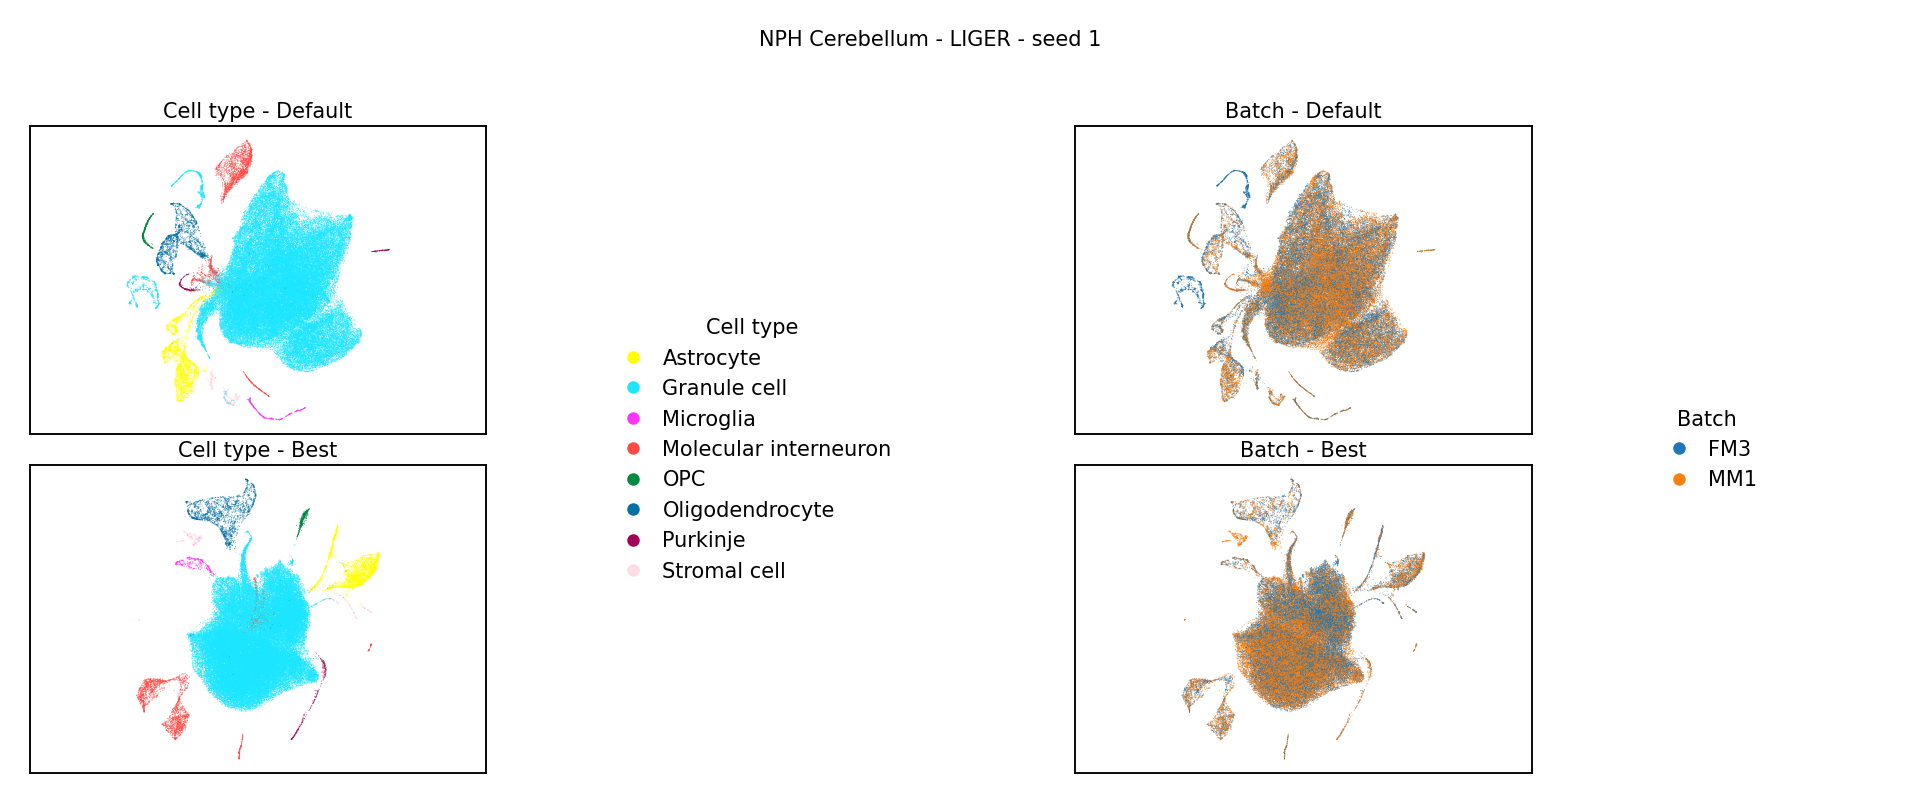

png           /ubc/cs/research/beaver/projects/Single-cell-i...
svg           /ubc/cs/research/beaver/projects/Single-cell-i...
n_cells                                                   84619
cell_types                                                    8
batches                                                       2
point_size                                                 0.05
Name: saved_figure, dtype: object

In [10]:
UMAP_SOURCE_TEXT_SIZE_PT = 5.0
UMAP_RASTER_DPI = 600


def ordered_categories(adata, key):
    values = adata.obs[key].astype(str)
    return tuple(sorted(pd.unique(values), key=str))


def category_palette(categories):
    if len(categories) <= len(sc.pl.palettes.default_102):
        colors = sc.pl.palettes.default_102[: len(categories)]
    else:
        cmap = plt.get_cmap("hsv", len(categories))
        colors = [cmap(index) for index in range(len(categories))]
    return dict(zip(categories, colors))


def scatter_panel(ax, adata, key, palette, title, order, point_size):
    values = adata.obs[key].astype(str).to_numpy()
    coordinates = adata.obsm["X_umap"]
    colors = [palette[value] for value in values[order]]
    ax.scatter(
        coordinates[order, 0],
        coordinates[order, 1],
        c=colors,
        s=point_size,
        alpha=0.78,
        linewidths=0,
        rasterized=False,
    )
    ax.set_title(
        title,
        fontsize=UMAP_SOURCE_TEXT_SIZE_PT,
        pad=2,
    )
    ax.set_aspect("equal", adjustable="datalim")
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(0.45)


def legend_handles(categories, palette):
    return [
        Line2D(
            [0],
            [0],
            marker="o",
            color="none",
            markerfacecolor=palette[category],
            markeredgecolor="none",
            markersize=3,
            label=category,
        )
        for category in categories
    ]


cell_categories = ordered_categories(adata_default, LABEL_KEY)
batch_categories = ordered_categories(adata_default, BATCH_KEY)
cell_palette = category_palette(cell_categories)
tab10_batch_colors = plt.get_cmap("tab10").colors
if len(batch_categories) > len(tab10_batch_colors):
    raise ValueError(
        "tab10 does not contain enough colors for all batch categories."
    )
batch_palette = dict(
    zip(batch_categories, tab10_batch_colors)
)

cell_legend_columns = 2 if len(cell_categories) > 18 else 1
batch_legend_columns = 2 if len(batch_categories) > 18 else 1
max_legend_rows = max(
    int(np.ceil(len(cell_categories) / cell_legend_columns)),
    int(np.ceil(len(batch_categories) / batch_legend_columns)),
)
figure_height = max(2.8, 0.18 * max_legend_rows)
figure = plt.figure(figsize=(8.0, figure_height), dpi=250)
grid = figure.add_gridspec(
    2,
    4,
    width_ratios=(1.0, 0.82, 1.0, 0.55),
    hspace=0.10,
    wspace=0.28,
)
cell_default_axis = figure.add_subplot(grid[0, 0])
cell_best_axis = figure.add_subplot(grid[1, 0])
cell_legend_axis = figure.add_subplot(grid[:, 1])
batch_default_axis = figure.add_subplot(grid[0, 2])
batch_best_axis = figure.add_subplot(grid[1, 2])
batch_legend_axis = figure.add_subplot(grid[:, 3])

plot_order = np.random.default_rng(SEED).permutation(
    adata_default.n_obs
)
if adata_default.n_obs <= 20_000:
    point_size = 0.10
elif adata_default.n_obs <= 40_000:
    point_size = 0.07
elif adata_default.n_obs <= 100_000:
    point_size = 0.05
else:
    point_size = 0.03

scatter_panel(
    cell_default_axis,
    adata_default,
    LABEL_KEY,
    cell_palette,
    "Cell type - Default",
    plot_order,
    point_size,
)
scatter_panel(
    cell_best_axis,
    adata_best,
    LABEL_KEY,
    cell_palette,
    "Cell type - Best",
    plot_order,
    point_size,
)
scatter_panel(
    batch_default_axis,
    adata_default,
    BATCH_KEY,
    batch_palette,
    "Batch - Default",
    plot_order,
    point_size,
)
scatter_panel(
    batch_best_axis,
    adata_best,
    BATCH_KEY,
    batch_palette,
    "Batch - Best",
    plot_order,
    point_size,
)

cell_legend_axis.axis("off")
cell_legend_axis.legend(
    handles=legend_handles(cell_categories, cell_palette),
    title="Cell type",
    loc="center left",
    frameon=False,
    fontsize=UMAP_SOURCE_TEXT_SIZE_PT,
    title_fontsize=UMAP_SOURCE_TEXT_SIZE_PT,
    ncol=cell_legend_columns,
    columnspacing=0.9,
    handletextpad=0.4,
)
batch_legend_axis.axis("off")
batch_legend_axis.legend(
    handles=legend_handles(batch_categories, batch_palette),
    title="Batch",
    loc="center left",
    frameon=False,
    fontsize=UMAP_SOURCE_TEXT_SIZE_PT,
    title_fontsize=UMAP_SOURCE_TEXT_SIZE_PT,
    ncol=batch_legend_columns,
    columnspacing=0.9,
    handletextpad=0.4,
)

figure.suptitle(
    f"{DATASET_DISPLAY} - {METHOD_NAME} - seed {SEED}",
    fontsize=UMAP_SOURCE_TEXT_SIZE_PT,
    y=0.995,
)
figure.savefig(
    PNG_PATH,
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)
figure.savefig(
    SVG_PATH,
    format="svg",
    dpi=UMAP_RASTER_DPI,
    bbox_inches="tight",
    facecolor="white",
)
plt.close(figure)

display(Image(filename=str(PNG_PATH)))
pd.Series(
    {
        "png": str(PNG_PATH),
        "svg": str(SVG_PATH),
        "n_cells": adata_default.n_obs,
        "cell_types": len(cell_categories),
        "batches": len(batch_categories),
        "point_size": point_size,
    },
    name="saved_figure",
)


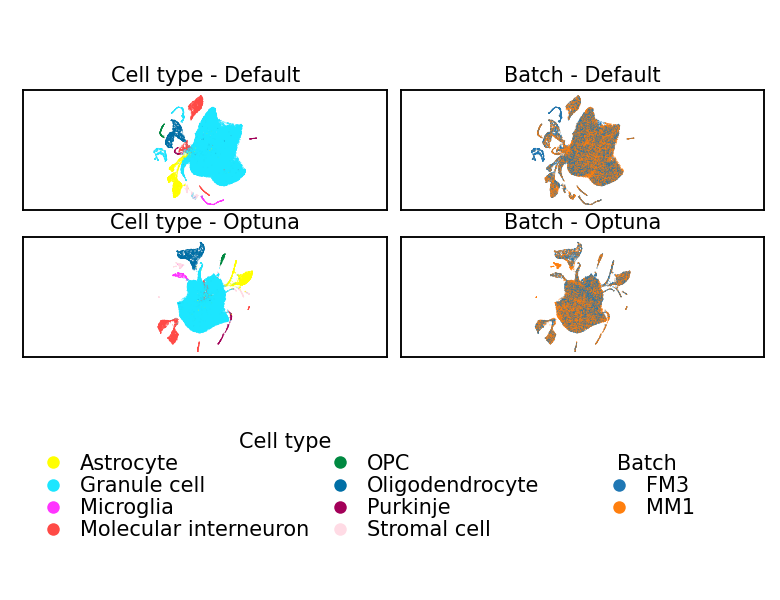

png            /ubc/cs/research/beaver/projects/Single-cell-i...
svg            /ubc/cs/research/beaver/projects/Single-cell-i...
n_cells                                                    84619
cell_types                                                     8
batches                                                        2
point_size                                                  0.05
panel_label                                               Optuna
suptitle                                                   False
Name: saved_revised_figure, dtype: object

In [11]:
revised_figure = plt.figure(
    figsize=(6.5 / 2.5, 2.0),
    dpi=250,
)
revised_grid = revised_figure.add_gridspec(
    3,
    4,
    height_ratios=(1.0, 1.0, 1.7),
    width_ratios=(1.0, 1.0, 1.0, 1.0),
    hspace=0.18,
    wspace=0.08,
)
revised_cell_default_axis = revised_figure.add_subplot(revised_grid[0, 0:2])
revised_cell_optuna_axis = revised_figure.add_subplot(revised_grid[1, 0:2])
revised_cell_legend_axis = revised_figure.add_subplot(revised_grid[2, 0:3])
revised_batch_default_axis = revised_figure.add_subplot(revised_grid[0, 2:4])
revised_batch_optuna_axis = revised_figure.add_subplot(revised_grid[1, 2:4])
revised_batch_legend_axis = revised_figure.add_subplot(revised_grid[2, 3])

scatter_panel(
    revised_cell_default_axis,
    adata_default,
    LABEL_KEY,
    cell_palette,
    "Cell type - Default",
    plot_order,
    point_size,
)
scatter_panel(
    revised_cell_optuna_axis,
    adata_best,
    LABEL_KEY,
    cell_palette,
    "Cell type - Optuna",
    plot_order,
    point_size,
)
scatter_panel(
    revised_batch_default_axis,
    adata_default,
    BATCH_KEY,
    batch_palette,
    "Batch - Default",
    plot_order,
    point_size,
)
scatter_panel(
    revised_batch_optuna_axis,
    adata_best,
    BATCH_KEY,
    batch_palette,
    "Batch - Optuna",
    plot_order,
    point_size,
)

revised_cell_legend_axis.axis("off")
revised_cell_legend_axis.legend(
    handles=legend_handles(cell_categories, cell_palette),
    title="Cell type",
    loc="center left",
    frameon=False,
    fontsize=UMAP_SOURCE_TEXT_SIZE_PT,
    title_fontsize=UMAP_SOURCE_TEXT_SIZE_PT,
    ncol=2,
    columnspacing=0.5,
    handletextpad=0.3,
    labelspacing=0.1,
    borderaxespad=0,
)
revised_batch_legend_axis.axis("off")
revised_batch_legend_axis.legend(
    handles=legend_handles(batch_categories, batch_palette),
    title="Batch",
    loc="center left",
    frameon=False,
    fontsize=UMAP_SOURCE_TEXT_SIZE_PT,
    title_fontsize=UMAP_SOURCE_TEXT_SIZE_PT,
    ncol=batch_legend_columns,
    columnspacing=0.5,
    handletextpad=0.3,
    labelspacing=0.1,
    borderaxespad=0,
)

REVISED_FIGURE_STEM = f"{FIGURE_STEM}_optuna_no_suptitle"
REVISED_PNG_PATH = FIGURE_ROOT / f"{REVISED_FIGURE_STEM}.png"
REVISED_SVG_PATH = FIGURE_ROOT / f"{REVISED_FIGURE_STEM}.svg"

revised_figure.subplots_adjust(
    left=0.03,
    right=0.98,
    bottom=0.02,
    top=0.85,
)
revised_figure.savefig(
    REVISED_PNG_PATH,
    dpi=300,
    facecolor="white",
)
revised_figure.savefig(
    REVISED_SVG_PATH,
    format="svg",
    dpi=UMAP_RASTER_DPI,
    facecolor="white",
)
plt.close(revised_figure)

display(Image(filename=str(REVISED_PNG_PATH)))
pd.Series(
    {
        "png": str(REVISED_PNG_PATH),
        "svg": str(REVISED_SVG_PATH),
        "n_cells": adata_default.n_obs,
        "cell_types": len(cell_categories),
        "batches": len(batch_categories),
        "point_size": point_size,
        "panel_label": "Optuna",
        "suptitle": False,
    },
    name="saved_revised_figure",
)
